# Tarea 25 Regresion logistica

In [155]:
# load libraries 
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [156]:
# load data set from drugs.csv file
drugs_data_frame = pd.read_csv('drugs.csv')
drugs_data_frame.sample(5)

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
136,55,F,HIGH,HIGH,10.977,drugB
199,40,F,LOW,NORMAL,11.349,drugX
122,34,M,NORMAL,HIGH,22.456,drugY
124,53,F,HIGH,NORMAL,12.495,drugB
129,32,F,NORMAL,HIGH,7.477,drugX


In [157]:
# set the columns to used as feature matrix X and target variable Y
feature_names = drugs_data_frame.columns.to_list()
feature_names.remove('Drug')

X = drugs_data_frame[feature_names].values
y = drugs_data_frame['Drug']

In [158]:
# Preprocessing to generate numerical values from categorical values
from sklearn import preprocessing

sex_codfication = preprocessing.LabelEncoder()
sex_codfication.fit(['F', 'M'])
X[:, 1] = sex_codfication.transform(X[:, 1])

bp_status_codfication = preprocessing.LabelEncoder()
bp_status_codfication.fit(['HIGH', 'LOW', 'NORMAL'])
X[:, 2] = bp_status_codfication.transform(X[:, 2])

cholesterol_status_codfication = preprocessing.LabelEncoder()
cholesterol_status_codfication.fit(['HIGH', 'NORMAL'])
X[:, 3] = bp_status_codfication.transform(X[:, 3])



In [159]:
# convert the drugs to local - 0, for drugA, drugB, drugC and foringer - 1 for drugX and drugY

custom_map = {
    'drugA':0,
    'drugB':0,
    'drugC':0,
    'drugX':1,
    'drugY':1,
}  
print(drugs_data_frame[0:5])
y = drugs_data_frame['Drug'].map(custom_map)


   Age Sex      BP Cholesterol  Na_to_K   Drug
0   23   F    HIGH        HIGH   25.355  drugY
1   47   M     LOW        HIGH   13.093  drugC
2   47   M     LOW        HIGH   10.114  drugC
3   28   F  NORMAL        HIGH    7.798  drugX
4   61   F     LOW        HIGH   18.043  drugY


In [160]:
# Build the trainig and testing sets 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

## Función para evaluar un modelo

In [161]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn import metrics

from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

def test_logistic_regression(solver):
    model = LogisticRegression(solver = solver)
    clf = model.fit(X_train, y_train)

    # Prediction 
    y_hat = model.predict(X_test)
    
    # print the regression coefficients 
    print(f'Intercept (beta_0): {model.intercept_}\n' )
    print(f'Coefficients (beta_0, beta_1, ...): {model.coef_}\n' )

    # Evaluate the score of the model
    score = model.score(X_test, y_test)
    print(f'Score: {score}')

    # Report of classification
    print(classification_report(y_test, y_hat, target_names=['local', 'foringer']))

    y_probs = model.predict_proba(X_test)[:,1]
    y_probs = np.round(y_probs)
    
    y_test2 = y_test.to_numpy()
    y_test2 = [int(x) for x in y_test2]

    fpr, tpr, thresholds = roc_curve(y_test, y_probs)
    auc = roc_auc_score(y_test, y_probs)
    plt.plot([0,1],[0,1],'k--')
    plt.plot(fpr, tpr, marker='.', label= 'Roc curve (area = %0.2f)' %auc)
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.legend(loc='lower right')
    plt.title('ROC curve for Linear regression')
    plt.show()



# Regresion logistica

## Sag solvelver

Intercept (beta_0): [-0.32346386]

Coefficients (beta_0, beta_1, ...): [[-0.03862692 -0.1664701   1.0344575   0.24423311  0.15665675]]

Score: 0.9
              precision    recall  f1-score   support

       local       1.00      0.60      0.75        10
    foringer       0.88      1.00      0.94        30

    accuracy                           0.90        40
   macro avg       0.94      0.80      0.84        40
weighted avg       0.91      0.90      0.89        40



/home/hugo/miniconda3/envs/my_env/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


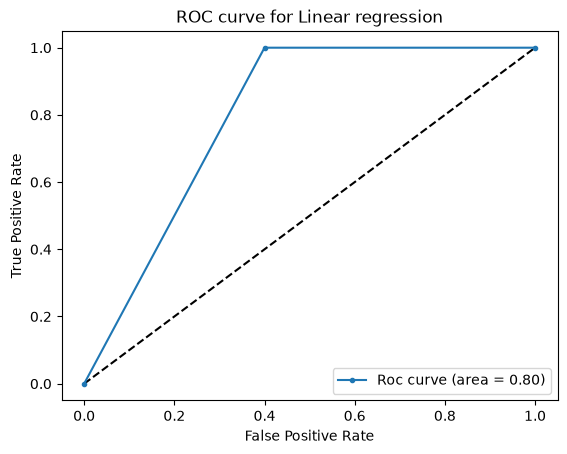

In [162]:
test_logistic_regression('sag')

## Newton-cg solver

Intercept (beta_0): [-12.29572689]

Coefficients (beta_0, beta_1, ...): [[0.00979882 0.16554353 3.59116076 1.37057387 0.68009248]]

Score: 0.975
              precision    recall  f1-score   support

       local       1.00      0.90      0.95        10
    foringer       0.97      1.00      0.98        30

    accuracy                           0.97        40
   macro avg       0.98      0.95      0.97        40
weighted avg       0.98      0.97      0.97        40



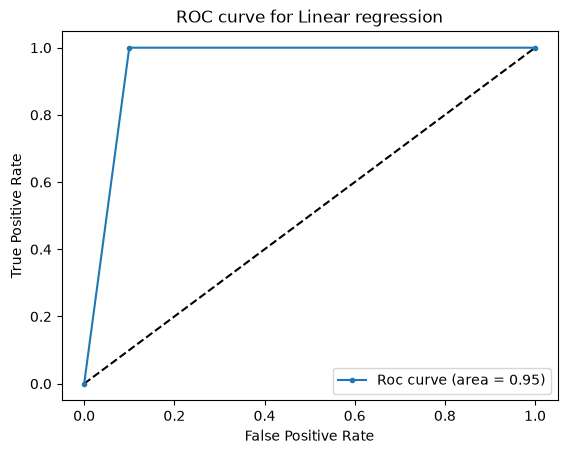

In [163]:
test_logistic_regression('newton-cg')

## liblinear solver

Intercept (beta_0): [-3.41460337]

Coefficients (beta_0, beta_1, ...): [[-0.02878688 -0.275728    2.0957794   0.64003784  0.27586817]]

Score: 0.975
              precision    recall  f1-score   support

       local       1.00      0.90      0.95        10
    foringer       0.97      1.00      0.98        30

    accuracy                           0.97        40
   macro avg       0.98      0.95      0.97        40
weighted avg       0.98      0.97      0.97        40



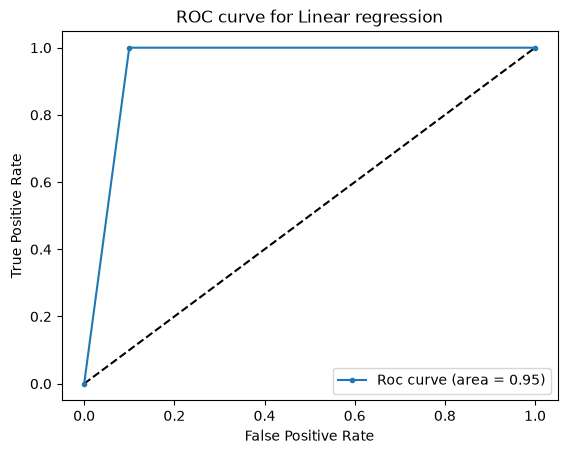

In [164]:
test_logistic_regression('liblinear')

## Saga solver 

Intercept (beta_0): [-0.14962776]

Coefficients (beta_0, beta_1, ...): [[-0.03463623 -0.09686416  0.66315351  0.15317385  0.15196667]]

Score: 0.9
              precision    recall  f1-score   support

       local       1.00      0.60      0.75        10
    foringer       0.88      1.00      0.94        30

    accuracy                           0.90        40
   macro avg       0.94      0.80      0.84        40
weighted avg       0.91      0.90      0.89        40



/home/hugo/miniconda3/envs/my_env/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


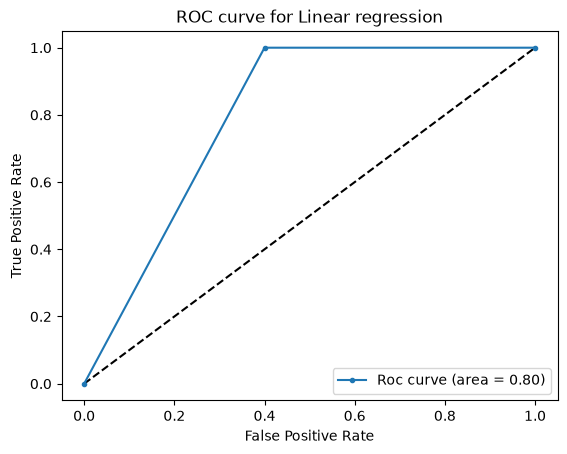

In [165]:
test_logistic_regression('saga')

## lbfgs solver

Intercept (beta_0): [-12.29756995]

Coefficients (beta_0, beta_1, ...): [[0.00980431 0.16557227 3.59155507 1.37073191 0.68018728]]

Score: 0.975
              precision    recall  f1-score   support

       local       1.00      0.90      0.95        10
    foringer       0.97      1.00      0.98        30

    accuracy                           0.97        40
   macro avg       0.98      0.95      0.97        40
weighted avg       0.98      0.97      0.97        40



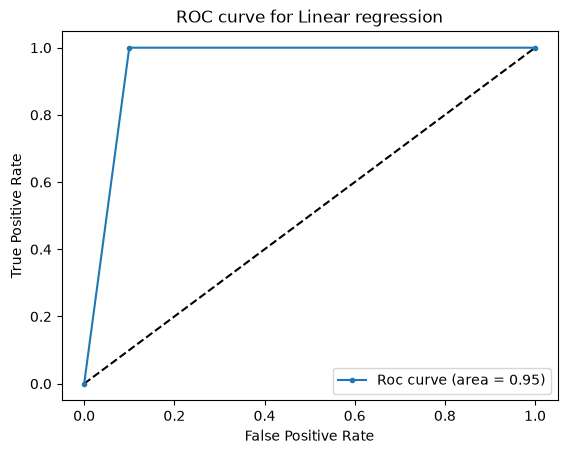

In [166]:
test_logistic_regression('lbfgs')

# Resultados 

| Solver  |  Acuracy (F1-score)  | Comentarios  |
|---------|-----------|----------|
| SAG |   0.90  |   En este caso los medicamentos locales tienen un menor **f1-score**      |
| Newton-cg  |     0.97     |    Ambos caso estan equilibrados     |
| liblinear  |     0.97    |   Similar al anterior     |
| saga |     0.90  |     En este caso los medicamentos locales tienen un menor **f1-score**   |
| lbfgs |     0.97  |   Similar al caso  Newton-cg  |

El solver que se recomienda usar es **Newton-cg** por que tiene un **f1-score = 0.97** y ambas clases estan equilibradas, mientas los otros solvers tienen un **f1-score = 0.75** para la categoria locales y **f1-score = 0.94** para extrangeros.